# Проверка качества данных интернет-магазина

## Цель исследования

Перед проведением анализа продаж необходимо оценить качество исходных данных и определить ограничения, которые могут повлиять на достоверность бизнес-показателей.

В рамках исследования я проверяю:

1. Структуру таблиц, пропуски и дубликаты.
2. Связи между заказами, клиентами и товарами.
3. Согласованность финансовых показателей между таблицами `orders` и `order_items`.
4. Соответствие количества товаров в заказах и товарных позициях.
5. Зависимость обнаруженных расхождений от характеристик заказов.
6. Различия между результатами проверки исходных CSV-файлов в Python и данных после загрузки в PostgreSQL.

## Используемые инструменты

- Python
- pandas
- matplotlib
- PostgreSQL — для дополнительной проверки результатов

## Ожидаемый результат

Выявить потенциальные проблемы качества данных, оценить их масштаб и сформулировать рекомендации по дальнейшему использованию данных в аналитике.

In [ ]:
#ИССЛЕДОВАНИЕ СТРУКТУРЫ ДАННЫХ
# Загрузка данных 
import pandas as pd
from pathlib import Path

# Указываем путь к папке
DATA_DIR = Path("../archive")

orders = pd.read_csv(DATA_DIR / "ecommerce_sales_customer_analytics_150k.csv")
customers = pd.read_csv(DATA_DIR / "customer_master.csv")
items = pd.read_csv(DATA_DIR / "order_items.csv")
products = pd.read_csv(DATA_DIR / "product_catalog.csv")
stats = pd.read_csv(DATA_DIR / "dataset_statistics.csv")

# Словарь с таблицами
tables = {
    "orders" : orders,
    "customers" : customers,
    "items" : items,
    "products" : products,
    "stats" : stats
}

#Проверяем сколько строк и столбцов в каждой таблице
for name, df in tables.items():
    print(f"{name}: {df.shape[0]:,} строк, {df.shape[1]} столбцов")

orders: 138,116 строк, 46 столбцов
customers: 25,000 строк, 11 столбцов
items: 397,569 строк, 12 столбцов
products: 1,175 строк, 9 столбцов
stats: 1 строк, 11 столбцов


In [ ]:
#СТРУКТУРА ТАБЛИЦ 
for name, df in tables.items():
    print(f"\n---{name.upper()}---")
    
    display(df.head()) # Более читаемый и интерактивный вывод таблиц 
    df.info()

    print(f"Полные дубликаты:", df.duplicated().sum())

    gaps = pd.DataFrame({
        "gaps_cnt": df.isna().sum(),
        "gaps_pct": df.isna().mean() * 100
    })

    display(
        gaps[gaps["gaps_cnt"] > 0].sort_values("gaps_pct", ascending = False))


---ORDERS---


,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,...,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,...,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,...,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69,Female,Premium,...,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44,True,6
3,ORD-567636,2023-01-21,07:20:26,Completed,Social Media,CUST-023928,Jennifer Smith,65,Male,Consumer,...,53.34,34.39,20.85,546.52,277.84,247.83,45.35,5638.30,True,7
4,ORD-820028,2022-05-13,09:46:21,Completed,Social Media,CUST-012730,Jessica Wang,34,Female,Consumer,...,133.63,421.35,23.03,2785.27,1231.88,1530.36,54.94,13240.10,True,8


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138116 entries, 0 to 138115
Data columns (total 46 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   order_id                  138116 non-null  object 
 1   order_date                138116 non-null  object 
 2   order_time                138116 non-null  object 
 3   order_status              138116 non-null  object 
 4   sales_channel             138116 non-null  object 
 5   customer_id               138116 non-null  object 
 6   customer_name             138116 non-null  object 
 7   customer_age              138116 non-null  int64  
 8   gender                    138116 non-null  object 
 9   customer_segment          138116 non-null  object 
 10  customer_type             138116 non-null  object 
 11  customer_city             138116 non-null  object 
 12  customer_state            138116 non-null  object 
 13  customer_country          138116 non-null  o

,gaps_cnt,gaps_pct
return_status,128654,93.149237
return_reason,128654,93.149237
coupon_code,110502,80.006661
campaign_name,83233,60.263112
delivery_days,24557,17.779982
customer_rating,24557,17.779982
estimated_delivery_days,24557,17.779982
customer_review,24557,17.779982
review_sentiment,24557,17.779982



---CUSTOMERS---


,customer_id,customer_name,customer_age,gender,customer_segment,customer_city,customer_state,customer_country,region,customer_postal_code,customer_acquisition_cost
0,CUST-000001,Donna Miller,54,Female,Consumer,Laurenland,Dubai,UAE,South,11253,13.58
1,CUST-000002,Joseph James,61,Male,Consumer,Lake Peter,Lower Saxony,Germany,North,47778,27.45
2,CUST-000003,Daniel Smith,47,Male,Consumer,Seanview,North Rhine,Germany,West,13900,31.53
3,CUST-000004,David Lopez,30,Male,VIP,Hawkinshaven,Pennsylvania,USA,East,53984,16.02
4,CUST-000005,Dakota Davis,55,Female,Consumer,New Carlymouth,Florida,USA,South,50994,41.34


... (10 outputs left out)


---STATS---


,Total Transactions,Total Columns,Total Customers,Total Products Used,Date Range,Total Revenue,Total Profit,Average Order Value,Average Rating,Return Rate,Cancellation Rate
0,138116,46,24911,138116,2021-01-01 to 2025-12-31,"$177,134,263.74","$76,146,395.76","$1,282.50",3.68,6.85%,6.08%


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1 entries, 0 to 0
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Total Transactions   1 non-null      int64  
 1   Total Columns        1 non-null      int64  
 2   Total Customers      1 non-null      int64  
 3   Total Products Used  1 non-null      int64  
 4   Date Range           1 non-null      object 
 5   Total Revenue        1 non-null      object 
 6   Total Profit         1 non-null      object 
 7   Average Order Value  1 non-null      object 
 8   Average Rating       1 non-null      float64
 9   Return Rate          1 non-null      object 
 10  Cancellation Rate    1 non-null      object 
dtypes: float64(1), int64(4), object(6)
memory usage: 220.0+ bytes
Полные дубликаты: 0


,gaps_cnt,gaps_pct


In [ ]:
print(orders["return_status"].value_counts(dropna=False))

return_status
NaN         128654
Returned      9462
Name: count, dtype: int64


### Анализ пропусков в данных о возвратах

В столбцах `return_status` и `return_reason` отсутствуют значения для 128 654 заказов (93,15%).

Дополнительная проверка показала, что у 9 462 заказов (6,85%) указан статус `Returned`.

Таким образом, в данных зафиксировано 9 462 заказа со статусом возврата. Для остальных заказов информация о возврате отсутствует. Эти пропуски могут быть связаны с тем, что возврат не оформлялся, однако для окончательного подтверждения необходимо проверить логику заполнения полей.

In [ ]:
delivery_check = (
    orders.groupby("order_status")
    .agg(
        total_orders=("order_id", "count"),
        missing_delivery=("delivery_days", lambda x: x.isna().sum()),
        missing_rating=("customer_rating", lambda x: x.isna().sum())
    )
)

delivery_check["missing_delivery_pct"] = (
    delivery_check["missing_delivery"]
    / delivery_check["total_orders"] * 100
)

delivery_check["missing_rating_pct"] = (
    delivery_check["missing_rating"]
    / delivery_check["total_orders"] * 100
)

display(delivery_check.round(2))

,total_orders,missing_delivery,missing_rating,missing_delivery_pct,missing_rating_pct
order_status,,,,,
Cancelled,8398,8398,8398,100.0,100.0
Completed,113559,0,0,0.0,0.0
Pending,6697,6697,6697,100.0,100.0
Returned,9462,9462,9462,100.0,100.0


**Анализ пропусков в данных о доставке и оценках**

В пяти столбцах (`delivery_days`, `estimated_delivery_days`, `customer_rating`, `customer_review`, `review_sentiment`) обнаружено по 24 557 пропусков (17,78%).

Дополнительная проверка связи пропусков со статусами заказов показала:

- У всех 113 559 заказов со статусом `Completed` заполнены поля `delivery_days` и `customer_rating`.
- У заказов со статусами `Cancelled`, `Pending` и `Returned` эти два поля не заполнены (100% пропусков).

**Вывод:** пропуски в проверенных полях связаны со статусом заказа, поэтому автоматически заменять их средними значениями или нулями некорректно.

Для анализа сроков доставки и клиентских оценок целесообразно отдельно рассматривать завершённые заказы (`Completed`). Причины отсутствия информации у возвращённых заказов требуют дополнительного изучения.

In [ ]:
#ПРОВЕРКА СВЯЗЕЙ МЕЖДУ ТАБЛИЦАМИ 
check = {
    "orders_without_customers": (~orders["customer_id"].isin(customers["customer_id"])).sum(), # Проверка заказов, оформленных на несуществующих клиентов 
    "items_without_orders": (~items["order_id"].isin(orders["order_id"])).sum(), # Проверка привязки товаров, к несуществующие номера
    "items_without_products": (~items["product_id"].isin(products["product_id"])).sum() # Проверка проданных товаров, которых нет в каталоге
}
print(check)
# Все три проверки связей вернули 0; другие аспекты качества данных проверяются отдельно

{'orders_without_customers': np.int64(0), 'items_without_orders': np.int64(0), 'items_without_products': np.int64(0)}


In [ ]:
#ОБНАРУЖЕННЫЕ ФИНАНСОВЫЕ РАСХОЖДЕНИЯ НА УРОВНЕ ЗАКАЗОВ
item_totals = (
items.groupby("order_id", as_index=False)
.agg(
items_net_sales=("net_sales", "sum"),
items_quantity=("quantity", "sum")
)
) # Считает для каждого отдельного заказа сумму и количество проданных товаров

reconciliation = orders[
["order_id", "order_status", "currency",
"net_sales", "quantity"]
].merge(
item_totals,
on="order_id",
how="left",
validate="one_to_one"
) # Объединяем таблицы заказы и агрегированный состав заказов, validate - проверка, чтобы order_id, не дублировался в таблицах 

reconciliation["revenue_diff"] = (
    reconciliation["net_sales"] - reconciliation["items_net_sales"]
) # Разница суммы заказов

reconciliation["has_mismatch"] = (
    reconciliation["revenue_diff"].abs() > 0.02
) # Отсечение ошибок округления и сохранение всех заказов с ошибками 

print(f"Заказы с расхождением:", reconciliation["has_mismatch"].sum())

display(reconciliation.groupby("order_status")["has_mismatch"].agg(["sum", "mean"]))

Заказы с расхождением: 11226


,sum,mean
order_status,,
Cancelled,658,0.078352
Completed,9267,0.081605
Pending,527,0.078692
Returned,774,0.081801


In [ ]:
# 1. Сверяем количество товаров
reconciliation["quantity_diff"] = (
    reconciliation["quantity"]
    - reconciliation["items_quantity"]
)

# 2. Рассчитываем масштаб расхождений
total_orders = len(reconciliation) 

mismatched_orders = reconciliation[
    reconciliation["has_mismatch"]
]

print(
    "Доля проблемных заказов:",
    round(len(mismatched_orders) / total_orders * 100, 2),
    "%"
)

# Денежные расхождения не суммируем между разными валютами.

print(
    "Заказы с расхождениями количества:",
    (reconciliation["quantity_diff"] != 0).sum()
)

# 3. Проверяем направление расхождений
print(
    reconciliation.loc[
        reconciliation["has_mismatch"],
        "revenue_diff"
    ].describe()
)

# 4. Смотрю примеры
display(
    reconciliation.loc[
        reconciliation["has_mismatch"]
    ].head(10)
)

Доля проблемных заказов: 8.13 %
Сумма абсолютных финансовых расхождений: 15264613.55
Заказы с расхождениями количества: 11226
count    11226.000000
mean     -1359.755349
std       1234.364874
min     -11139.310000
25%      -1853.960000
50%      -1015.995000
75%       -483.912500
max        -13.810000
Name: revenue_diff, dtype: float64


,order_id,order_status,currency,net_sales,quantity,items_net_sales,items_quantity,revenue_diff,has_mismatch,quantity_diff
12,ORD-163733,Completed,GBP,486.48,7,1579.70,13,-1093.22,True,-6
18,ORD-652783,Completed,USD,4497.43,14,6419.61,24,-1922.18,True,-10
19,ORD-537228,Completed,EUR,144.13,1,567.43,8,-423.30,True,-7
23,ORD-697815,Completed,USD,4286.91,8,4396.29,11,-109.38,True,-3
45,ORD-509719,Completed,CAD,1478.86,4,2665.42,10,-1186.56,True,-6
53,ORD-726019,Completed,AUD,5498.50,20,6822.36,26,-1323.86,True,-6
69,ORD-150153,Completed,USD,107.22,2,2278.15,11,-2170.93,True,-9
83,ORD-772475,Completed,USD,748.91,4,1971.20,13,-1222.29,True,-9
86,ORD-869225,Completed,USD,228.65,1,497.72,4,-269.07,True,-3
94,ORD-749446,Completed,GBP,1416.00,1,1845.91,4,-429.91,True,-3


In [ ]:
financial_mismatch = reconciliation["has_mismatch"]
quantity_mismatch = reconciliation["quantity_diff"] != 0

print(
    "Финансовые расхождения:",
    financial_mismatch.sum()
)

print(
    "Расхождения количества:",
    quantity_mismatch.sum()
)

print(
    "Оба типа расхождений:",
    (financial_mismatch & quantity_mismatch).sum()
)

print(
    "Только финансовые расхождения:",
    (financial_mismatch & ~quantity_mismatch).sum()
)

print(
    "Только расхождения количества:",
    (~financial_mismatch & quantity_mismatch).sum()
)

Финансовые расхождения: 11226
Расхождения количества: 11226
Оба типа расхождений: 11226
Только финансовые расхождения: 0
Только расхождения количества: 0


### Проверка взаимосвязи финансовых и количественных расхождений

При сверке таблиц `orders` и `order_items` обнаружено 11 226 заказов (8,13%) с финансовыми расхождениями более 0,02.

Дополнительная проверка показала, что все 11 226 заказов также имеют расхождения по количеству товаров. Заказов только с финансовыми или только с количественными расхождениями в исходных CSV-файлах не обнаружено.

**Вывод:** финансовые расхождения сопровождаются несоответствием количества товаров между таблицами. Это указывает на возможную проблему согласованности данных на уровне заказа и его товарных позиций.

Перед расчётом финансовых показателей необходимо определить, какая таблица является достоверным источником, и установить причины расхождений.

In [ ]:
extra_order_ids = [
    "ORD-448290",
    "ORD-179530",
    "ORD-428248",
    "ORD-761566",
    "ORD-575151",
    "ORD-802711",
    "ORD-739328",
    "ORD-133520",
    "ORD-705120",
    "ORD-362901"
]

csv_check = reconciliation[
    reconciliation["order_id"].isin(extra_order_ids)
][[
    "order_id",
    "net_sales",
    "items_net_sales",
    "revenue_diff",
    "quantity_diff",
    "has_mismatch"
]].copy()

display(csv_check.sort_values("order_id"))

,order_id,net_sales,items_net_sales,revenue_diff,quantity_diff,has_mismatch
86981,ORD-133520,11990.93,11990.93,0.000000e+00,0,False
67605,ORD-179530,12578.45,12578.45,0.000000e+00,0,False
136990,ORD-362901,11674.67,11674.67,-1.818989e-12,0,False
55084,ORD-428248,10242.46,10242.46,0.000000e+00,0,False
87244,ORD-448290,10208.65,10208.65,0.000000e+00,0,False
64097,ORD-575151,11410.86,11410.86,0.000000e+00,0,False
26516,ORD-705120,12604.07,12604.07,0.000000e+00,0,False
22060,ORD-739328,10992.26,10992.26,0.000000e+00,0,False
55512,ORD-761566,10520.84,10520.84,0.000000e+00,0,False
16578,ORD-802711,11293.34,11293.34,0.000000e+00,0,False


### Сравнение результатов Python и PostgreSQL

При проверке исходных CSV-файлов в Python обнаружено 11 226 заказов (8,13%) с финансовыми расхождениями более 0,02.

Повторная проверка данных в PostgreSQL выявила 11 236 заказов (8,14%).

Для исследования причины различия были отдельно проверены 10 дополнительных заказов.

**Результаты проверки:**
- В исходных CSV-файлах суммы заказов и их товарных позиций совпадают.
- Количество товаров также совпадает.
- В PostgreSQL для этих заказов обнаружены финансовые расхождения от 0,03 до 0,05.

**Вывод:** дополнительные расхождения возникают при сравнении данных после их загрузки в PostgreSQL. Вероятная причина — ограниченная точность типа `real` (`float4`), использованного для хранения денежных значений.

Для финансовых показателей в PostgreSQL рекомендуется использовать тип `numeric(18,2)`, позволяющий хранить денежные значения с фиксированной точностью.

In [ ]:
# Проверяю расхождения по валютам
currency_analysis = (
    reconciliation
    .groupby("currency")
    .agg(
        total_orders=("order_id", "count"),
        mismatched_orders=("has_mismatch", "sum"),
        total_revenue_diff=("revenue_diff", "sum"),  # Сумма внутри каждой валюты
        avg_revenue_diff=("revenue_diff", "mean")
    )
    .reset_index()
)

currency_analysis["mismatch_rate"] = (
    currency_analysis["mismatched_orders"]
    / currency_analysis["total_orders"] * 100
)

display(
    currency_analysis.sort_values(
        "mismatch_rate", ascending=False
    )
)
# Расхождения есть во всех валютах, частота расхождений не отличается кардинально 

,currency,total_orders,mismatched_orders,total_revenue_diff,avg_revenue_diff,mismatch_rate
0,AED,4172,354,-474355.58,-113.699803,8.485139
2,CAD,7015,589,-839447.12,-119.664593,8.396294
6,USD,82600,6746,-9131415.82,-110.549828,8.167070
4,GBP,20235,1624,-2194856.45,-108.468320,8.025698
1,AUD,6794,545,-705109.76,-103.784186,8.021784
3,EUR,11593,923,-1269577.92,-109.512458,7.961701
5,INR,5707,445,-649850.90,-113.869091,7.797442


In [ ]:
# Проверяю количество товарных позиций
items_count = (
    items.groupby("order_id")
    .size()
    .reset_index(name="item_rows")
)

if "item_rows" in reconciliation.columns:
    reconciliation = reconciliation.drop(columns=["item_rows"]) # Удаляю старые данные, теперь код будет работать, при повторных запусках


reconciliation = reconciliation.merge(
    items_count,
    on="order_id",
    how="left",
    validate="one_to_one"
)

display(
    reconciliation.groupby("has_mismatch")
    .agg(
        orders=("order_id", "count"),
        avg_item_rows=("item_rows", "mean"),
        avg_order_quantity=("quantity", "mean"),
        avg_items_quantity=("items_quantity", "mean")
    )
)


,orders,avg_item_rows,avg_order_quantity,avg_items_quantity
has_mismatch,,,,
False,126890,2.650430,5.619206,5.619206
True,11226,5.456619,5.570461,11.521913


### Связь расхождений с количеством товарных строк

В заказах с финансовыми расхождениями среднее число товарных строк составляет 5,46 против 2,65 в согласованных заказах. При этом количество единиц товаров в таблице заказов практически одинаково в обеих группах. Это указывает на возможное наличие дополнительных товарных позиций в `order_items`, но причину ещё необходимо проверить.

In [ ]:
# Проверяю валовые продажи
items["gross_sales_check"] = (
    items["quantity"] * items["unit_price"]
)

items["gross_sales_diff"] = (
    items["gross_sales"]
    - items["gross_sales_check"]
)

print(
    "Расхождений gross_sales:",
    (items["gross_sales_diff"].abs() > 0.02).sum()
)

display(items["gross_sales_diff"].describe())
# валовые продажи не отличаются, они согласованы с количеством и ценой, но в таблицах остается расхождение по количесвту 

Расхождений gross_sales: 0


count    3.975690e+05
mean    -3.562463e-16
std      4.639557e-14
min     -9.094947e-13
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      9.094947e-13
Name: gross_sales_diff, dtype: float64

In [ ]:
# Анализ частоты расхождений по количеству товарных строк

item_rows_analysis = (
    reconciliation
    .groupby("item_rows")
    .agg(
        total_orders=("order_id", "count"),
        mismatched_orders=("has_mismatch", "sum")
    )
    .reset_index()
)

item_rows_analysis["mismatch_rate"] = (
    item_rows_analysis["mismatched_orders"]
    / item_rows_analysis["total_orders"] * 100
)

display(item_rows_analysis)

,item_rows,total_orders,mismatched_orders,mismatch_rate
0,1,25352,0,0.000000
1,2,38588,415,1.075464
2,3,32921,1265,3.842532
3,4,20975,2077,9.902265
4,5,15109,2298,15.209478
5,6,2092,2092,100.000000
6,7,1492,1492,100.000000
7,8,875,875,100.000000
8,9,448,448,100.000000
9,10,180,180,100.000000


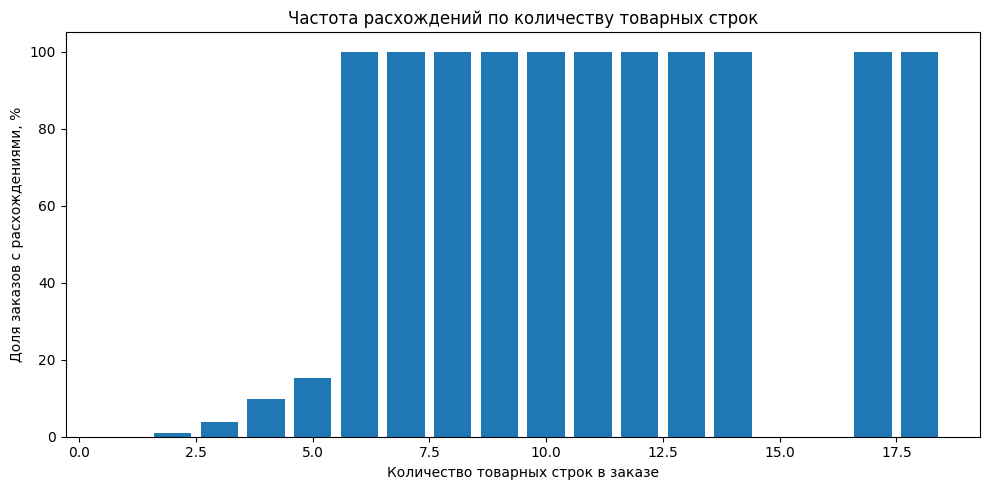

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    item_rows_analysis["item_rows"],
    item_rows_analysis["mismatch_rate"]
)

plt.xlabel("Количество товарных строк в заказе")
plt.ylabel("Доля заказов с расхождениями, %")
plt.title("Частота расхождений по количеству товарных строк")

plt.tight_layout()
plt.show()

### Вывод по частоте расхождений

Доля заказов с финансовыми расхождениями растёт вместе с количеством товарных строк. Для заказов с шестью и более строками она составляет 100% в исследуемом наборе данных.

Например, для заказов с двумя строками доля расхождений — 1,08%, с четырьмя — 9,90%, с пятью — 15,21%.

**Бизнес-риск:** использование несогласованных таблиц может искажать показатели продаж, особенно для многопозиционных заказов. **Следующее действие:** проверить правила формирования `orders` и `order_items` и установить достоверный источник данных.

## Итоговые выводы и рекомендации

- Проверки связей не выявили заказов без клиентов, товарных строк без заказов и товаров вне каталога.
- Пропуски в информации о доставке и оценках связаны со статусами заказов; заменять их нулями или средними значениями без проверки нельзя.
- В исходных CSV **11 226 заказов (8,13%)** имеют финансовые расхождения свыше 0,02 между `orders` и `order_items`. У всех этих заказов одновременно обнаружены расхождения по количеству товаров.
- В PostgreSQL найдено **11 236 (8,14%)** финансовых расхождений. Дополнительные 10 заказов согласованы в исходных CSV, но отличаются в PostgreSQL на 0,03–0,05. Вероятная причина — хранение денежных значений в `real` (`float4`); для окончательного доказательства нужно сравнить точные значения до и после импорта.
- Доля расхождений возрастает с числом товарных строк. Это требует проверки правил формирования заказов и их состава.

**Перед использованием данных в финансовой отчётности** следует установить достоверный источник выручки, исследовать причины несоответствий и хранить денежные показатели в точном десятичном типе (`numeric`, с подходящей точностью и масштабом). Суммы в разных валютах нельзя складывать без пересчёта по согласованным курсам.

**Воспроизведение:** CSV-файлы должны находиться в папке `archive` на один уровень выше каталога проекта. Ноутбук следует запускать с рабочей папкой `ecommerce-analytics`.